# M13.11 — Visualización del escalón inicial (clic) de SEOBNRv4_opt

Diagnóstico **descriptivo**: no es un contraste, no entra en la selección de variantes y no cambia el pre-registro de M13.11 (docs/experiments/M13_11_bayesian_reference.md). Reutiliza las funciones de `scripts/m13/m13_11_prepare_rows.py`: reconstrucción exacta de la fila con `build_g1_row` y la física de G3, la misma proyección, la misma ventana final de 4 s y el mismo procesado lineal de G3.

Formas de onda (todas SEOBNRv4_opt salvo R):
- **A**: la usada en la generación (`f_lower = 30 Hz`, sin taper). Empieza de golpe: escalón en t0.
- **S**: desde 20 Hz con `td_taper` (Kaiser, β = 8) hasta que la frecuencia instantánea cruza 28 Hz; alineada con A en fase y tiempo sub-muestra (`_opt_click_free_aligned`).
- **E**: desde 10 Hz, sin taper, alineada como S (`opt_extended_aligned`): aproxima una señal real que viene de frecuencias más bajas.
- **R**: SEOBNRv4_ROM con `f_lower = 30 Hz` (aproximante de la PE), en el dominio del tiempo, situada por su epoch (sin alinear).

A − S aísla el clic. Filas fijas: 409054 (corta, escalón 0,73), 400082 (corta), 422785 (media), 400026 (larga). La figura final usa las 180 filas del último `gates.json` con `diag_click`.

Ejecución: kernel de `gw-env`, celda a celda; `CBC_PE_DATA_ROOT` y `LAL_DATA_PATH` exportados en el kernel o fijados en la celda 1, antes de importar pycbc/lal. Lee el HDF5 de G3, el manifest y la caché GWOSC de los bloques de estas filas; no escribe nada.

In [1]:
# 1. Parámetros y entorno (antes de importar pycbc / lal)
import os
from pathlib import Path

os.environ.setdefault('CBC_PE_DATA_ROOT', '/data/vserrano/cbc_pe_data')
os.environ.setdefault('LAL_DATA_PATH', '/data/vserrano/cbc_pe_data/external/lal_data')

# Filas de ejemplo fijas: row id del HDF5 -> etiqueta
ROWS = {409054: 'corta, escalón 0,73', 400082: 'corta', 422785: 'media', 400026: 'larga'}
# gates.json de una ejecución con --diag-click (las 180 filas); None = el más reciente con diag_click
GATES_JSON = None
ZOOM_S = 0.05   # semiancho del zoom alrededor del inicio de A [s]

In [2]:
# 2. Importaciones y contrato (mismo setup que el script: G1, manifest, física de G3)
import argparse
import json
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import scripts.m13.m13_11_prepare_rows as pr
from pycbc.waveform import get_td_waveform
from pycbc.waveform.utils import frequency_from_polarizations

g1 = pr.g1
ns = argparse.Namespace(config=pr.DEFAULT_CONFIG, data_root=None, manifest=None,
                        allow_version_mismatch=False, mode='m13_11_click_visualization')
DATA_ROOT, spec_g1, df, TRAINIO, _, _ = pr.g6.setup(ns)
DETECTORS, DT, DT_I = pr.DETECTORS, g1.CONFIG.delta_t, pr.INTRINSIC_DELTA_T
OPT = g1.CONFIG.waveform_approximant
print('data root:', DATA_ROOT)
print('G3 trainio:', TRAINIO)
print('approximant:', OPT)

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain

data root: /data/vserrano/cbc_pe_data
G3 trainio: /data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5
approximant: SEOBNRv4_opt


In [3]:
# 3. Reconstrucción exacta de las filas y diagnóstico del clic (pr.diagnose_click, igual que --diag-click)
frame = pr.g3.adjust_processing_windows(df.loc[list(ROWS)], spec_g1)
psd_files, _ = pr.resolve_cached_psd_files(DATA_ROOT, frame)
injector = g1.SignalInjector(config=g1.CONFIG, rng=np.random.default_rng(0))  # inject no usa el rng
R = {}
with h5py.File(TRAINIO, 'r') as t:
    for index, row in frame.iterrows():
        X_row, meta, cap, opt_args = pr.capture_row(row, long_strains=pr.read_psd_intervals(row, psd_files),
                                                    psd_cache={})
        fs = pr.final_start_of(row)

        def crop(series, fs=fs):
            return pr.crop_to_final(series, fs, injector)

        s_opt = {ifo: crop(cap.signal['projection'].strains[ifo]) for ifo in DETECTORS}
        psd4 = {ifo: pr.psd_at_final_resolution(cap.psds[ifo]) for ifo in DETECTORS}
        X = np.asarray(t['X'][index], dtype=np.float64)
        d = pr.diagnose_click(row, opt_args, cap, s_opt, psd4, crop)['data']
        R[index] = dict(row=row, cap=cap, opt_args=opt_args, final_start=fs, X=X, click=d)
        snr_al, snr_pm, snr_t = d['snr_click_aligned_network'], d['snr_click_phasemax_network'], d['target_network_snr']
        print(f'{index} ({ROWS[index]}): max|X_row - X_G3| {np.abs(X_row - X).max():.2e}; SNR del clic alineado '
              f'{snr_al:.3f}, con fase maximizada {snr_pm:.3f}; SNR objetivo {snr_t:.2f}')

Processing window: context 1664/1664 -> 33408/33408 samples; final_start and final_center unchanged (max |diff| 0.00e+00 s)
409054 (corta, escalón 0,73): max|X_row - X_G3| 0.00e+00; SNR del clic alineado 7.533, con fase maximizada 6.831; SNR objetivo 24.49
400082 (corta): max|X_row - X_G3| 0.00e+00; SNR del clic alineado 2.574, con fase maximizada 2.505; SNR objetivo 11.08
422785 (media): max|X_row - X_G3| 0.00e+00; SNR del clic alineado 2.799, con fase maximizada 2.776; SNR objetivo 22.63
400026 (larga): max|X_row - X_G3| 0.00e+00; SNR del clic alineado 1.831, con fase maximizada 1.830; SNR objetivo 22.99


In [4]:
# 4. Utilidades de figura
def intrinsic_args(row, approximant=None):
    # Cara a cara, 1 Mpc, coa_phase 0, f_lower 30 Hz (como la parte intrínseca de diagnose_click).
    return dict(approximant=approximant or OPT, mass1=float(row['mass_1']), mass2=float(row['mass_2']),
                spin1z=float(row['spin_1z']), spin2z=float(row['spin_2z']), inclination=0.0, coa_phase=0.0,
                distance=1.0, delta_t=DT_I, f_lower=pr.INTRINSIC_F_LOWER)


def times(ts):
    return float(ts.start_time) + np.arange(len(ts)) * float(ts.delta_t)


def crossing(hp, hc, f0):
    # Primer instante con frecuencia instantánea >= f0 (mismo criterio que _opt_click_free).
    f = frequency_from_polarizations(hp, hc)
    i = np.flatnonzero(f.numpy() >= f0)
    return float(f.sample_times[i[0]]) if len(i) else np.nan


def on_common_grid(series):
    # Series en la misma rejilla sub-muestra (la de A): desplazamientos enteros, ceros hasta 2^k.
    t0 = min(float(s.start_time) for s in series.values())
    shift = {k: int(round((float(s.start_time) - t0) / float(s.delta_t))) for k, s in series.items()}
    n = int(2 ** np.ceil(np.log2(max(shift[k] + len(s) for k, s in series.items()))))
    out = {}
    for k, s in series.items():
        x = np.zeros(n)
        x[shift[k]:shift[k] + len(s)] = s.numpy()
        out[k] = x
    return out, n


def zoom(a, pairs, lo, hi):
    # pairs: [(t, y), ...]; límites del eje y a partir de lo visible en [lo, hi].
    m = max(np.abs(y[(tt >= lo) & (tt <= hi)]).max(initial=0.0) for tt, y in pairs)
    a.set_xlim(lo, hi)
    if m > 0:
        a.set_ylim(-1.1 * m, 1.1 * m)


def project(hp, hc, cap):
    # Mismos parámetros extrínsecos y t_c que la señal inyectada.
    return g1.DETECTOR_PROJECTOR.project(h_plus=hp, h_cross=hc, parameters=cap.params,
                                         geocentric_coalescence_time=cap.geocentric_time).strains


def L(strains, r):
    # Procesado lineal de G3 sin ruido ni z-score (pr.process_clean, como M13.6).
    return pr.process_clean(strains, processing_start=float(r['row']['processing_start']),
                            psds=r['cap'].psds, injector=injector)

409054 (corta, escalón 0,73): |A+(t0)| / max|A+| = 0.728
   alineación de S: {'delta_rad': -0.27542, 'sign': -1.0, 'coa_phase_shift_rad': 0.13771, 'residual_rad': 0.0, 'residual_ok': True, 'lag_samples': -3.37041, 'time_shift_s': -0.00082, 'common_segment_s': 0.33911}
   alineación de E: {'delta_rad': -2.40947, 'sign': -1.0, 'coa_phase_shift_rad': 1.20474, 'residual_rad': -0.0, 'residual_ok': True, 'lag_samples': -3.53325, 'time_shift_s': -0.00081, 'common_segment_s': 0.33911}


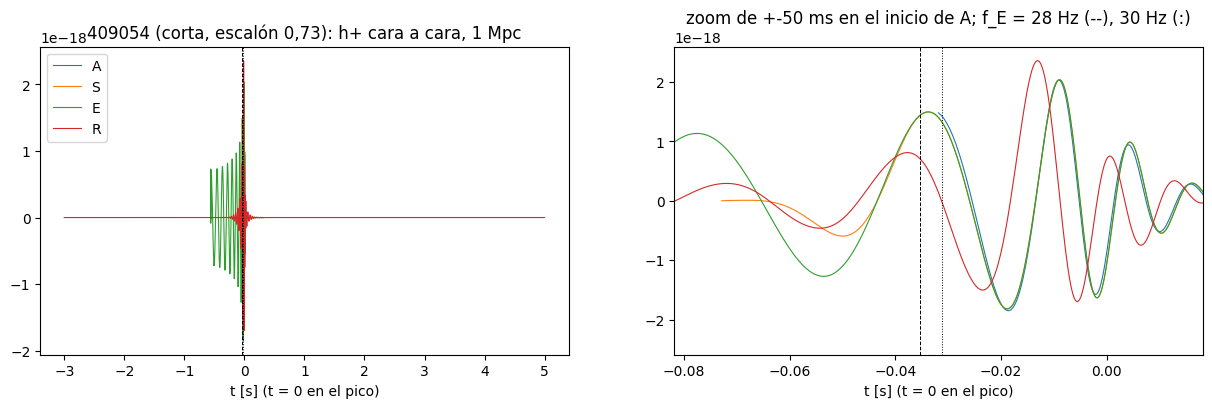

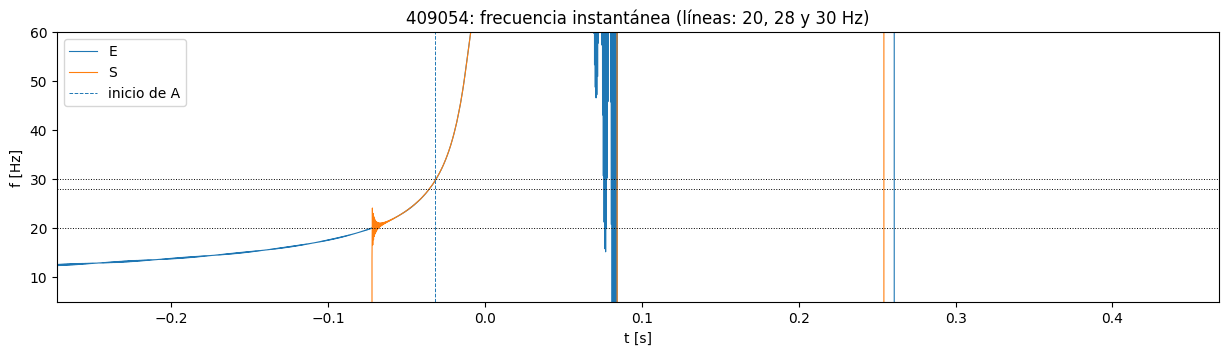

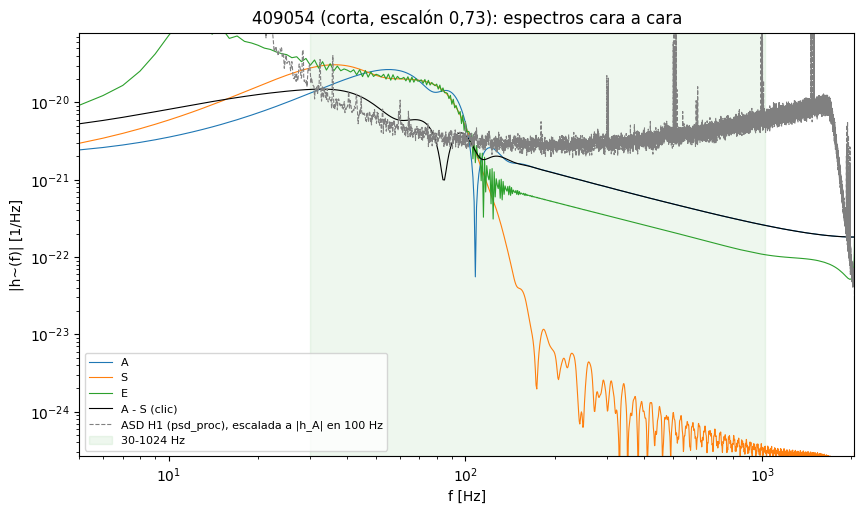

400082 (corta): |A+(t0)| / max|A+| = 0.632
   alineación de S: {'delta_rad': -0.07833, 'sign': -1.0, 'coa_phase_shift_rad': 0.03917, 'residual_rad': -0.0, 'residual_ok': True, 'lag_samples': -0.86391, 'time_shift_s': -0.00021, 'common_segment_s': 0.32788}
   alineación de E: {'delta_rad': 0.55329, 'sign': -1.0, 'coa_phase_shift_rad': -0.27665, 'residual_rad': 0.0, 'residual_ok': True, 'lag_samples': -1.11501, 'time_shift_s': -0.00022, 'common_segment_s': 0.32788}


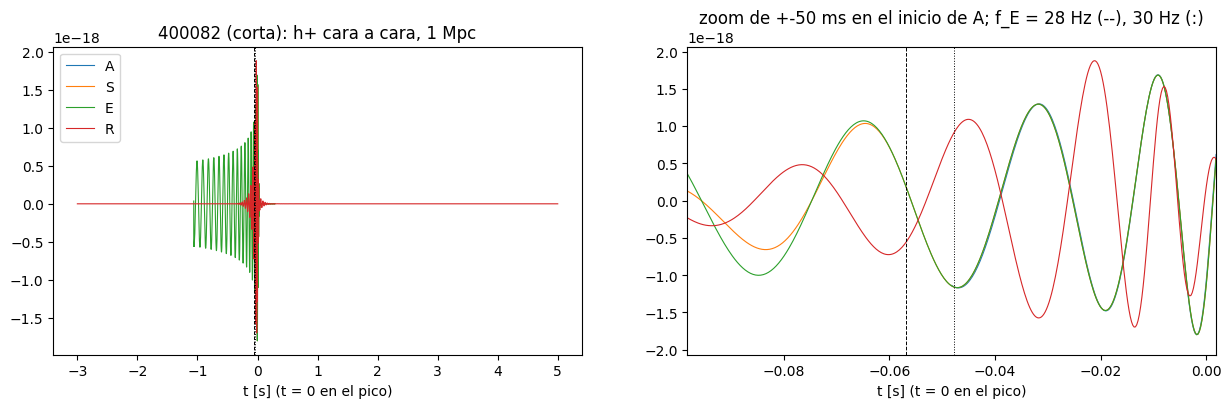

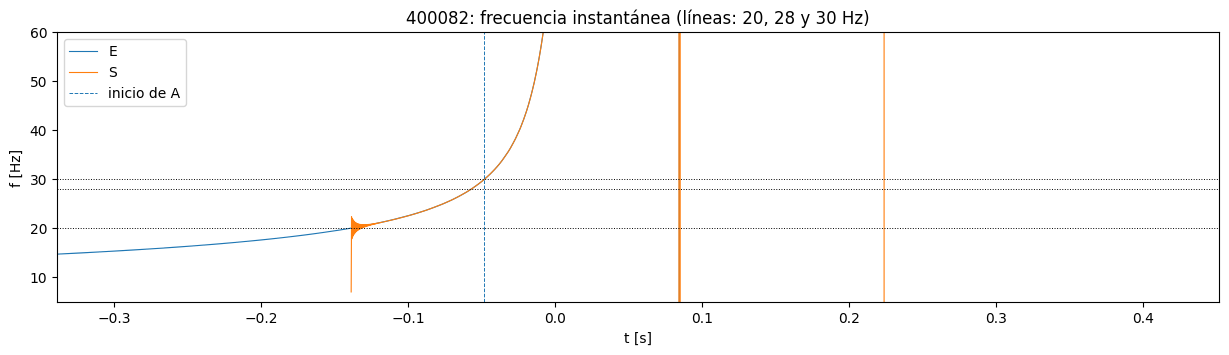

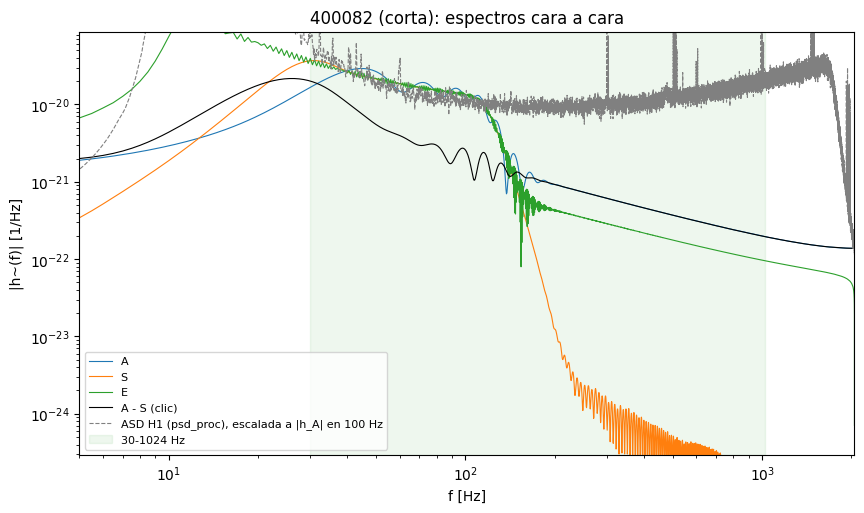

422785 (media): |A+(t0)| / max|A+| = 0.266
   alineación de S: {'delta_rad': -0.10237, 'sign': -1.0, 'coa_phase_shift_rad': 0.05119, 'residual_rad': -0.0, 'residual_ok': True, 'lag_samples': 0.13175, 'time_shift_s': -3e-05, 'common_segment_s': 0.34009}
   alineación de E: {'delta_rad': 0.45323, 'sign': -1.0, 'coa_phase_shift_rad': -0.22662, 'residual_rad': 0.0, 'residual_ok': True, 'lag_samples': 0.35723, 'time_shift_s': -2e-05, 'common_segment_s': 0.34009}


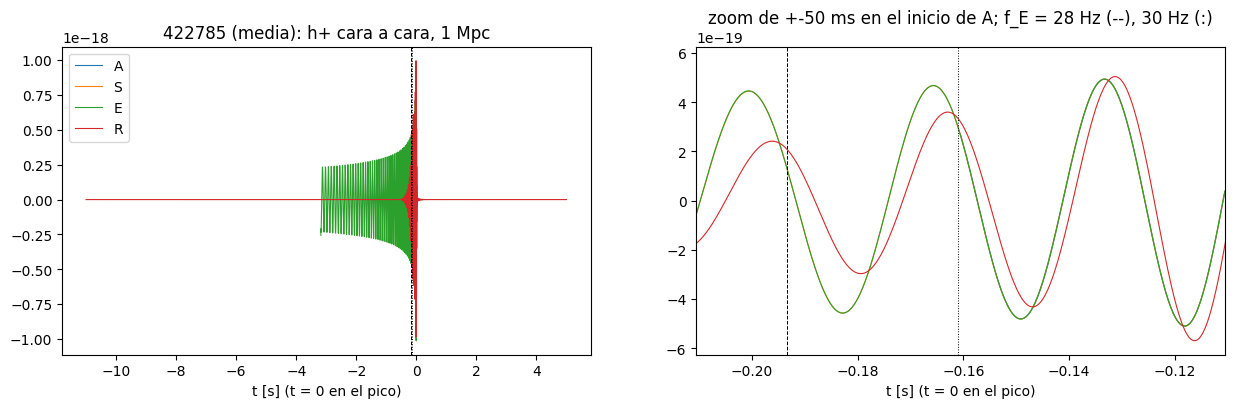

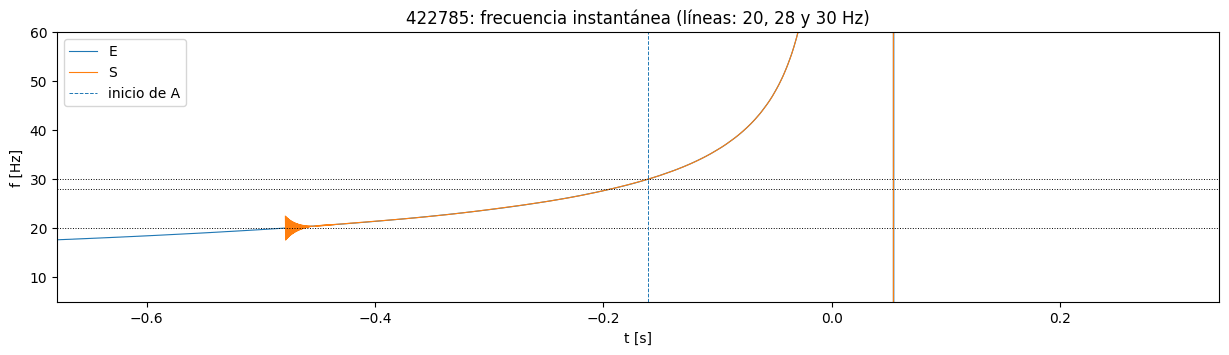

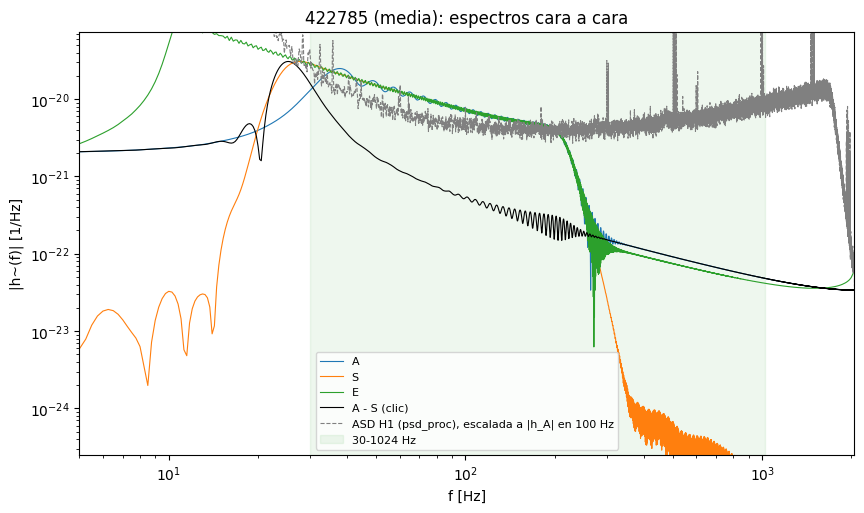

400026 (larga): |A+(t0)| / max|A+| = 0.243
   alineación de S: {'delta_rad': 3.01108, 'sign': -1.0, 'coa_phase_shift_rad': -1.50554, 'residual_rad': -0.0, 'residual_ok': True, 'lag_samples': 0.42529, 'time_shift_s': -0.0, 'common_segment_s': 0.85156}
   alineación de E: {'delta_rad': -0.48531, 'sign': -1.0, 'coa_phase_shift_rad': 0.24266, 'residual_rad': -0.0, 'residual_ok': True, 'lag_samples': -0.24568, 'time_shift_s': -1e-05, 'common_segment_s': 0.85156}


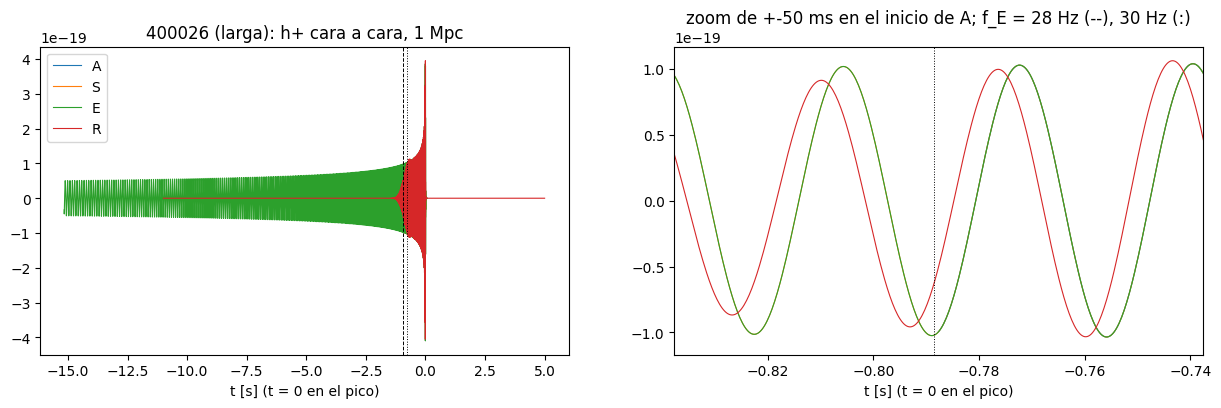

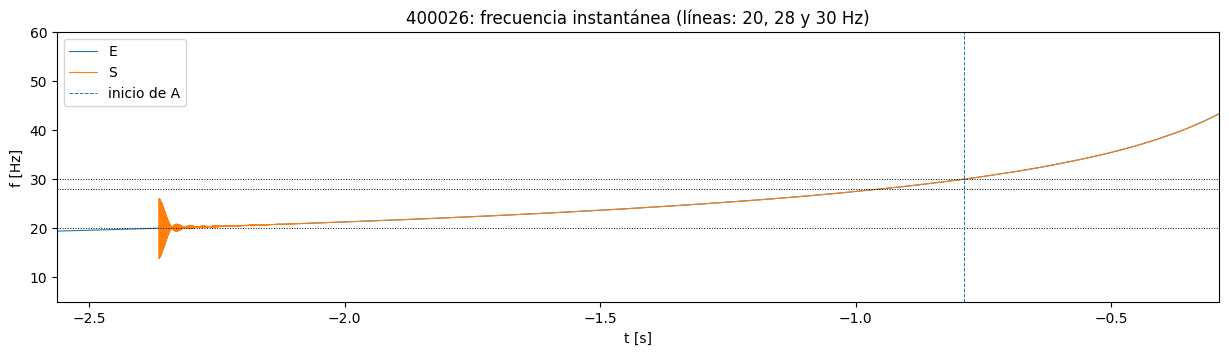

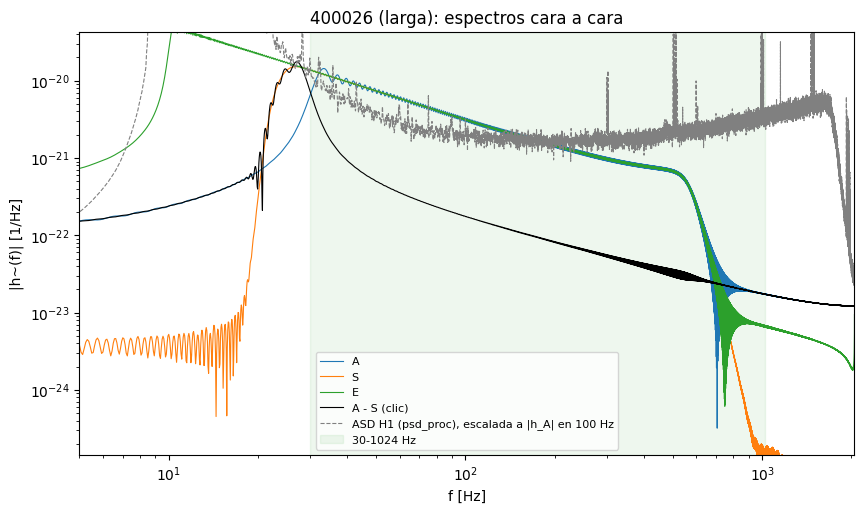

In [5]:
# 5. Intrínseco, cara a cara (paneles 1-3)
def rounded(diag):
    return {k: round(v, 5) if isinstance(v, float) else v for k, v in diag.items()}


for index, r in R.items():
    row = r['row']
    kw = intrinsic_args(row)
    A = get_td_waveform(**kw)
    S_hp, S_hc, s_al = pr._opt_click_free_aligned(kw)
    E_hp, E_hc, e_al = pr.opt_extended_aligned(kw)
    W = dict(A=A, S=(S_hp, S_hc), E=(E_hp, E_hc), R=get_td_waveform(**intrinsic_args(row, pr.ROM_APPROXIMANT)))
    tA = float(A[0].start_time)
    t28, t30 = crossing(E_hp, E_hc, 28.0), crossing(E_hp, E_hc, 30.0)
    step = abs(A[0][0]) / np.abs(A[0].numpy()).max()
    print(f'{index} ({ROWS[index]}): |A+(t0)| / max|A+| = {step:.3f}')
    print('   alineación de S:', rounded(s_al))
    print('   alineación de E:', rounded(e_al))

    # Panel 1: h+ completa y zoom de +-50 ms alrededor del inicio de A
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    pairs = [(times(hp), hp.numpy()) for hp, _ in W.values()]
    for name, (tt, y) in zip(W, pairs):
        for a in ax:
            a.plot(tt, y, lw=0.8, label=name)
    for a in ax:
        a.axvline(t28, color='k', ls='--', lw=0.7)
        a.axvline(t30, color='k', ls=':', lw=0.7)
        a.set_xlabel('t [s] (t = 0 en el pico)')
    zoom(ax[1], pairs, tA - ZOOM_S, tA + ZOOM_S)
    ax[0].set_title(f'{index} ({ROWS[index]}): h+ cara a cara, 1 Mpc')
    ax[1].set_title('zoom de +-50 ms en el inicio de A; f_E = 28 Hz (--), 30 Hz (:)')
    ax[0].legend(loc='upper left')
    plt.show()

    # Panel 2: frecuencia instantánea de E y S
    fig, a = plt.subplots(figsize=(15, 3.5))
    for name in ('E', 'S'):
        f = frequency_from_polarizations(*W[name])
        a.plot(f.sample_times.numpy(), f.numpy(), lw=0.8, label=name)
    for f0 in (20.0, 28.0, 30.0):
        a.axhline(f0, color='k', ls=':', lw=0.7)
    a.axvline(tA, color='C0', ls='--', lw=0.7, label='inicio de A')
    a.set_xlim(float(S_hp.start_time) - 0.2, tA + 0.5)
    a.set_ylim(5.0, 60.0)
    a.set_xlabel('t [s]')
    a.set_ylabel('f [Hz]')
    a.legend(loc='upper left')
    a.set_title(f'{index}: frecuencia instantánea (líneas: 20, 28 y 30 Hz)')
    plt.show()

    # Panel 3: espectros de A, S, E y del clic, con la ASD de H1 (psd_proc) escalada
    grid, n = on_common_grid({'A': A[0], 'S': S_hp, 'E': E_hp})
    f = np.fft.rfftfreq(n, DT_I)
    H = {k: np.abs(np.fft.rfft(x)) * DT_I for k, x in grid.items()}
    H['A - S (clic)'] = np.abs(np.fft.rfft(grid['A'] - grid['S'])) * DT_I
    psd = r['cap'].psds['H1']
    fp, asd = psd.sample_frequencies.numpy(), np.sqrt(psd.numpy())
    ok = (fp >= 5.0) & (asd > 0)
    scale = np.interp(100.0, f, H['A']) / np.interp(100.0, fp[ok], asd[ok])
    band = (f >= 5.0) & (f <= 2048.0)
    fig, a = plt.subplots(figsize=(10, 5.5))
    for k, y in H.items():
        a.loglog(f[band], y[band], lw=0.8, color='k' if 'clic' in k else None, label=k)
    a.loglog(fp[ok], scale * asd[ok], lw=0.8, ls='--', color='gray',
             label='ASD H1 (psd_proc), escalada a |h_A| en 100 Hz')
    a.axvspan(30.0, 1024.0, color='C2', alpha=0.08, label='30-1024 Hz')
    a.set_xlim(5.0, 2048.0)
    a.set_ylim(H['A'][band].max() * 1e-5, H['A'][band].max() * 3.0)
    a.set_xlabel('f [Hz]')
    a.set_ylabel('|h~(f)| [1/Hz]')
    a.legend(fontsize=8)
    a.set_title(f'{index} ({ROWS[index]}): espectros cara a cara')
    plt.show()

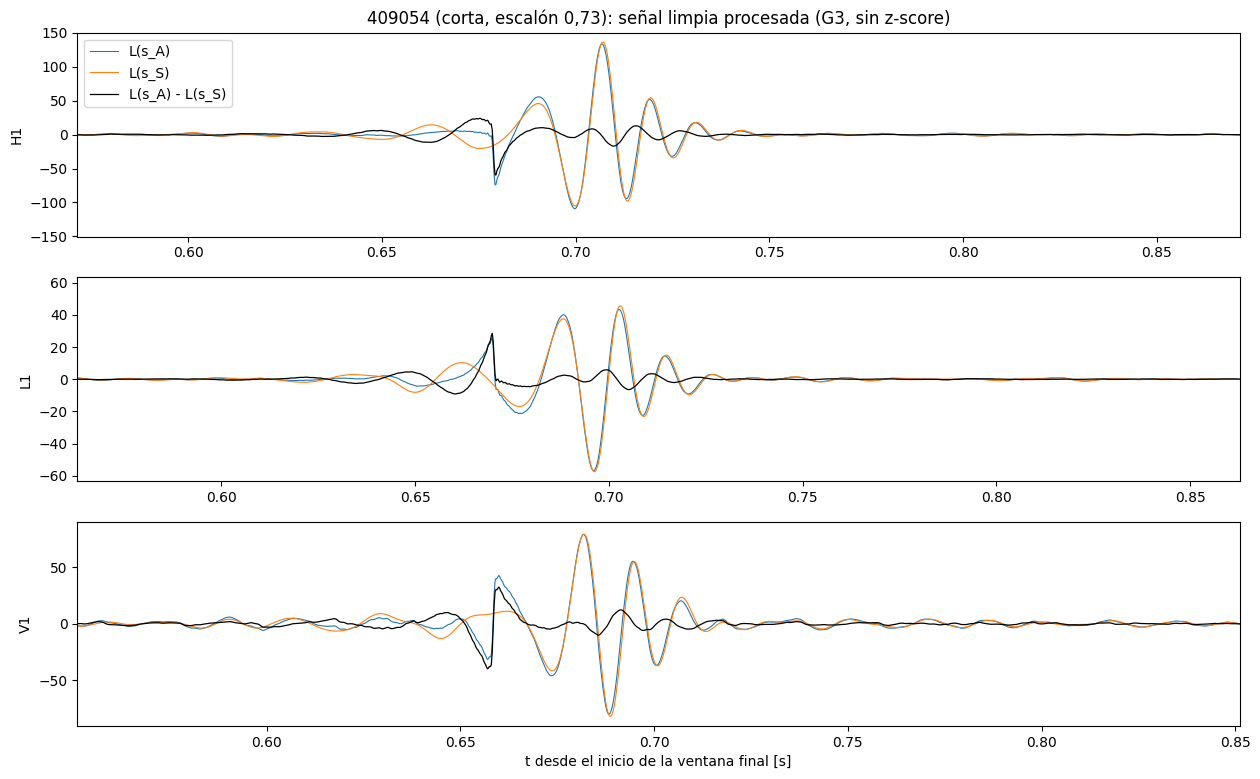

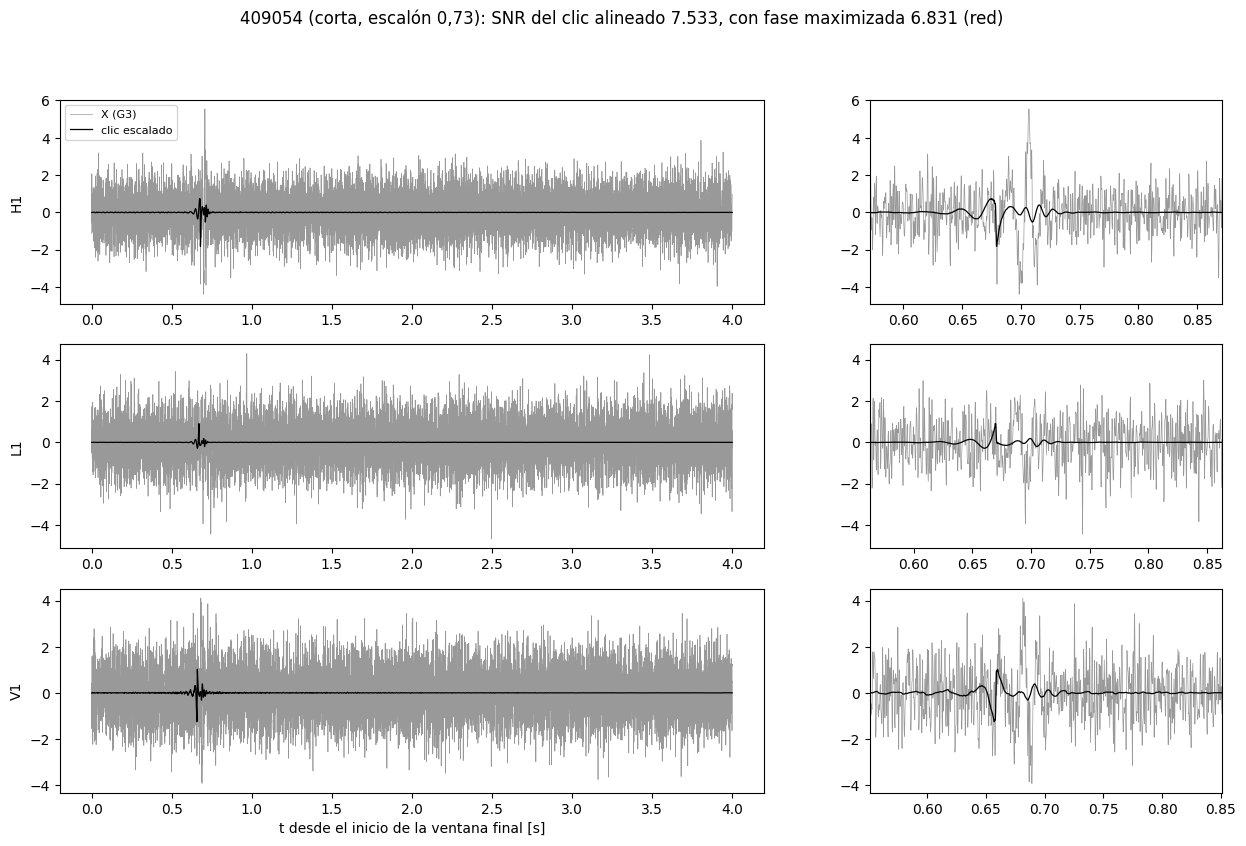

409054: max|L(s_E) - L(s_S)| / max|L(s_S)| = {'H1': 0.23878, 'L1': 0.05486, 'V1': 0.1625}


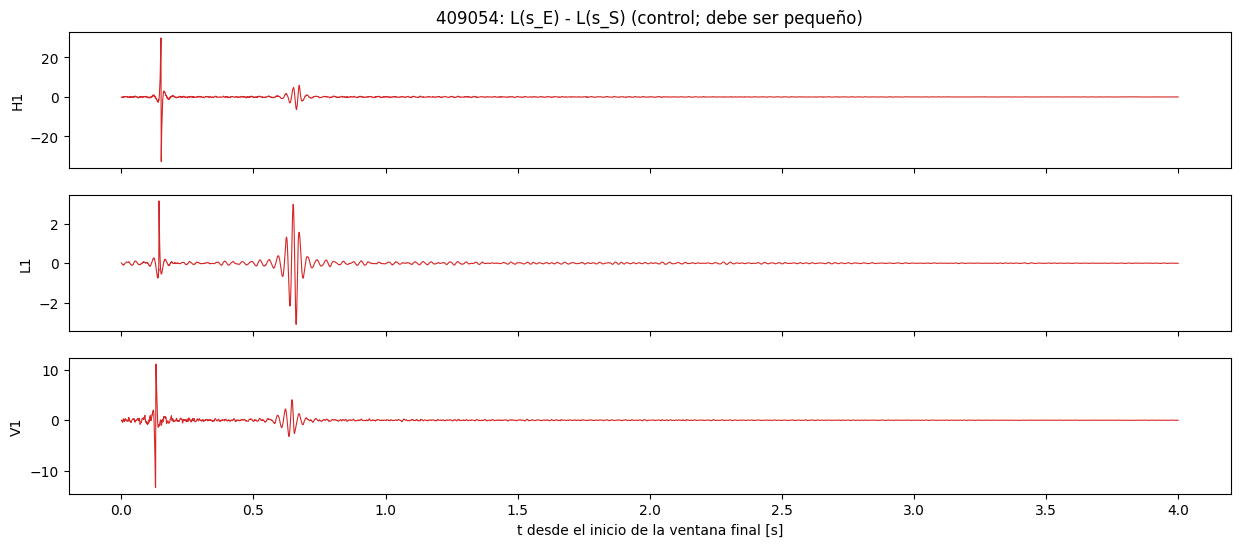

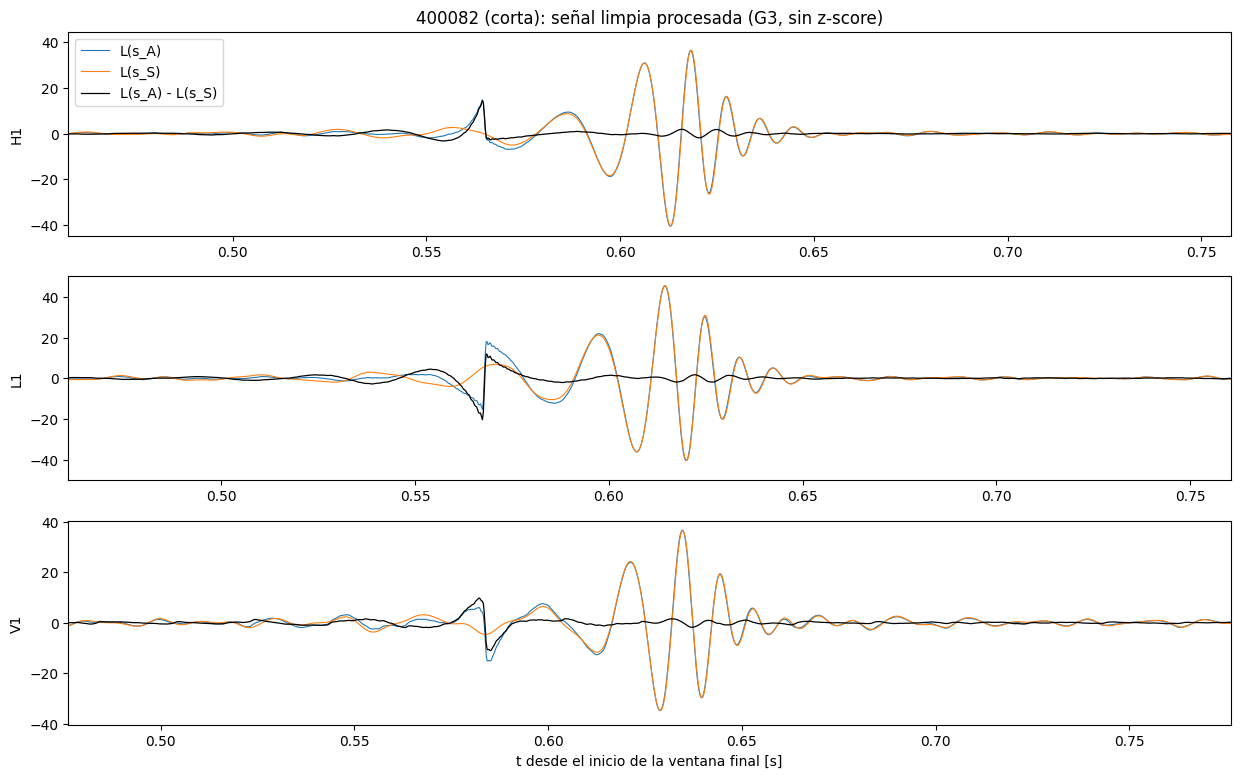

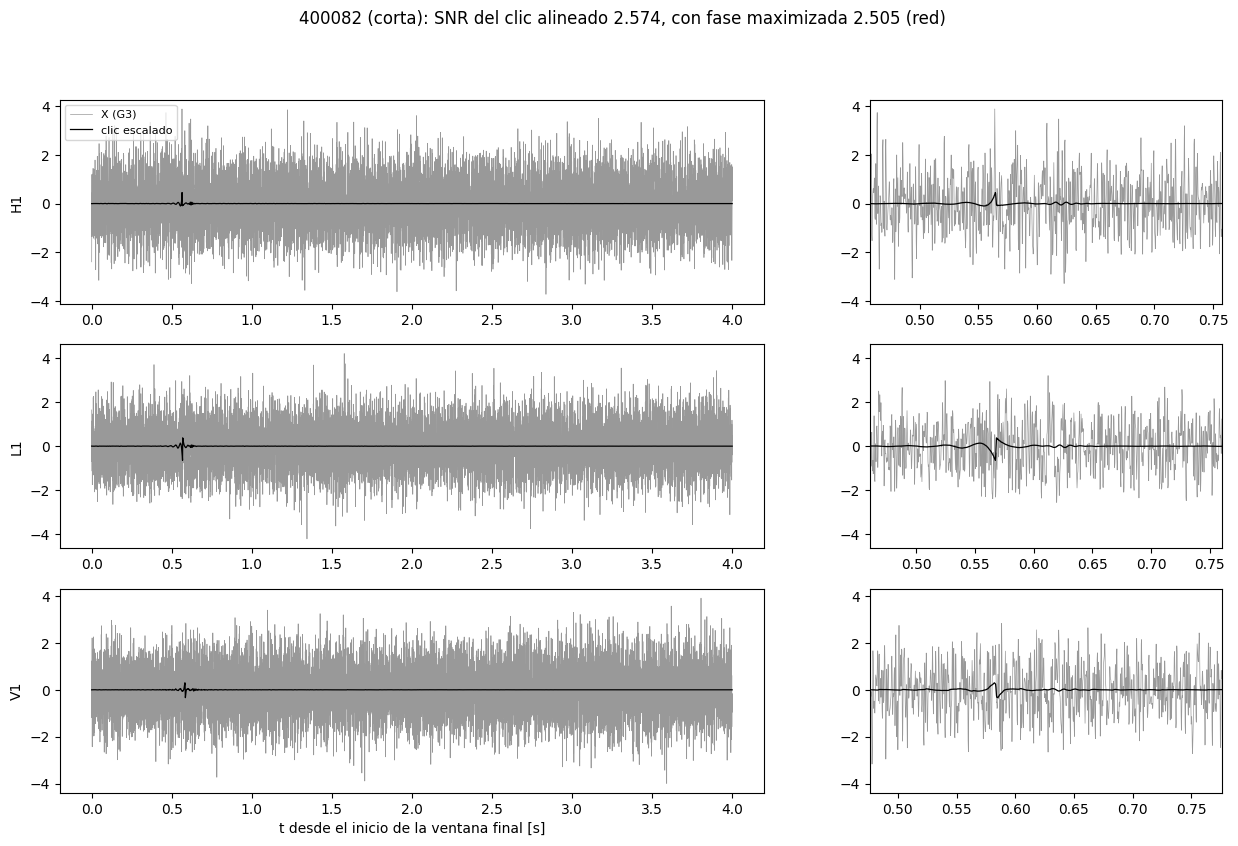

400082: max|L(s_E) - L(s_S)| / max|L(s_S)| = {'H1': 0.01115, 'L1': 0.01672, 'V1': 0.01055}


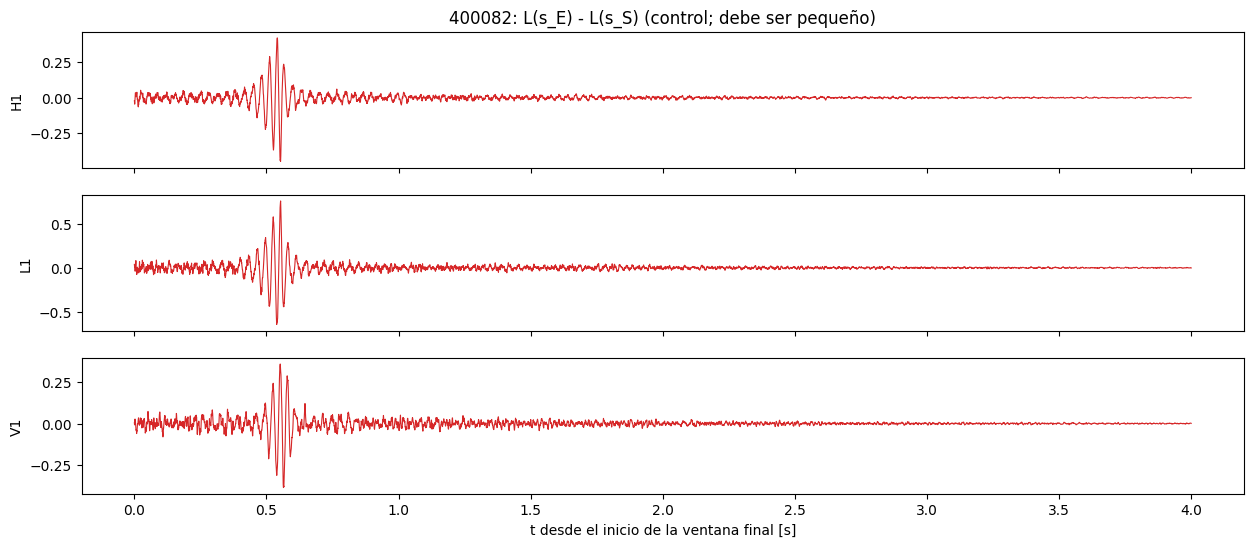

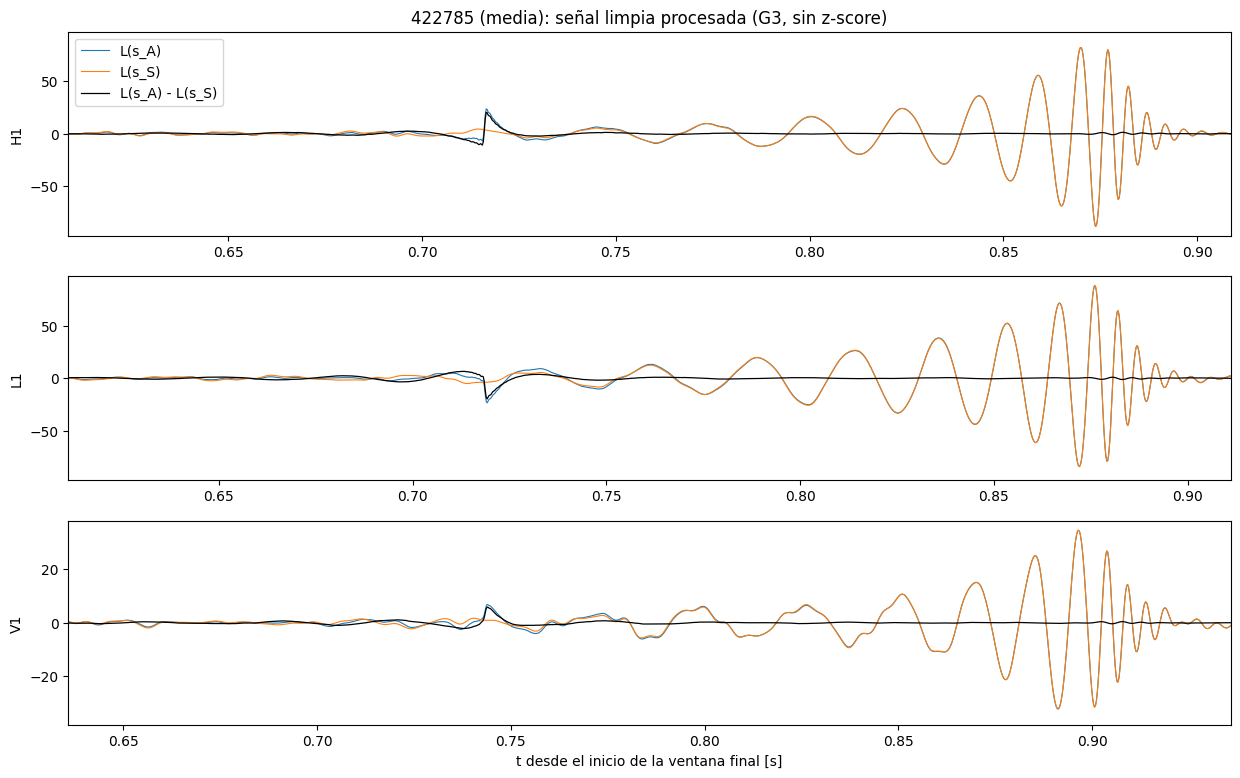

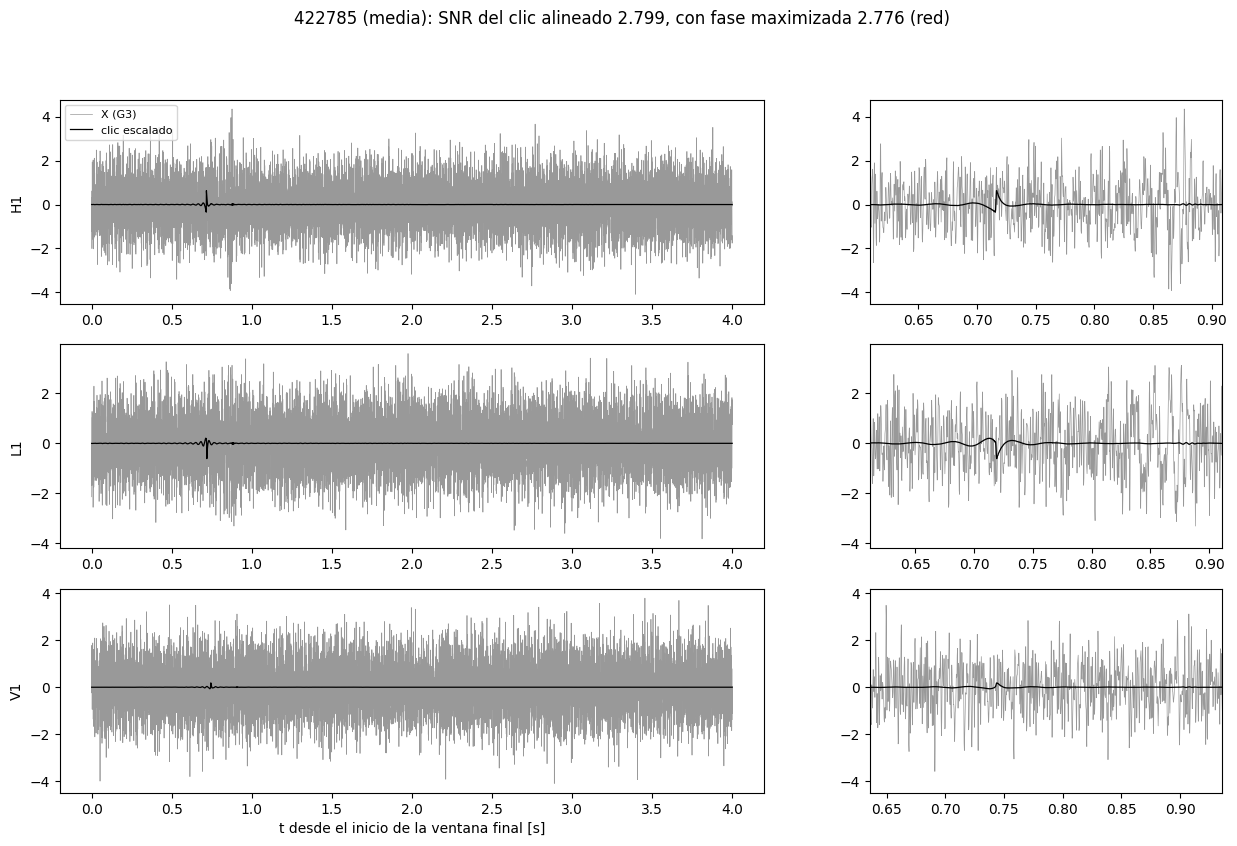

422785: max|L(s_E) - L(s_S)| / max|L(s_S)| = {'H1': 0.00104, 'L1': 0.00144, 'V1': 0.00141}


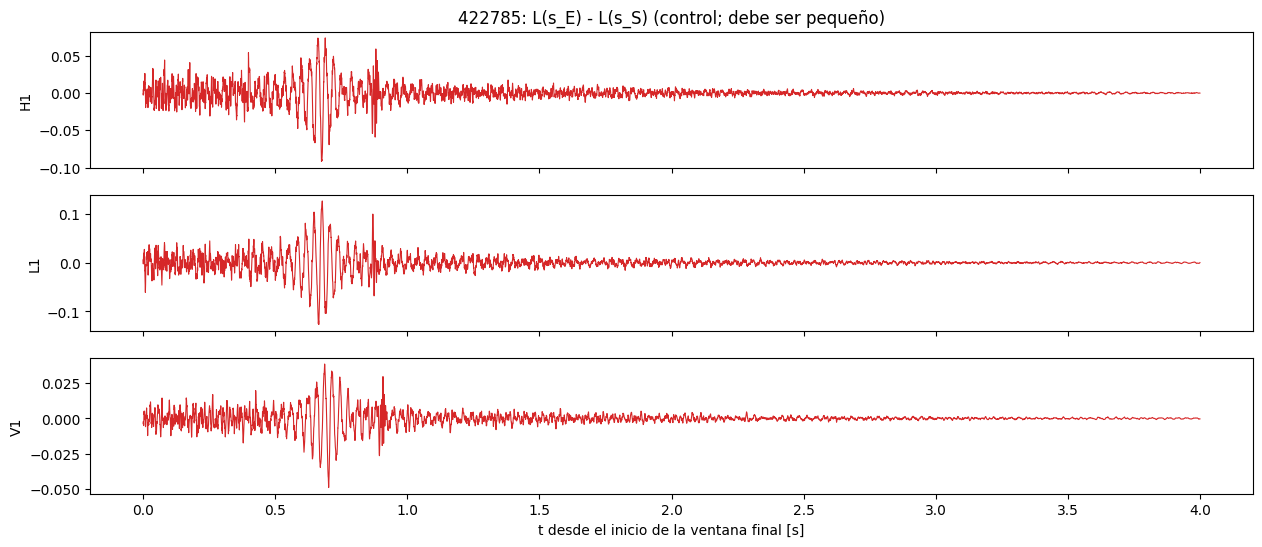

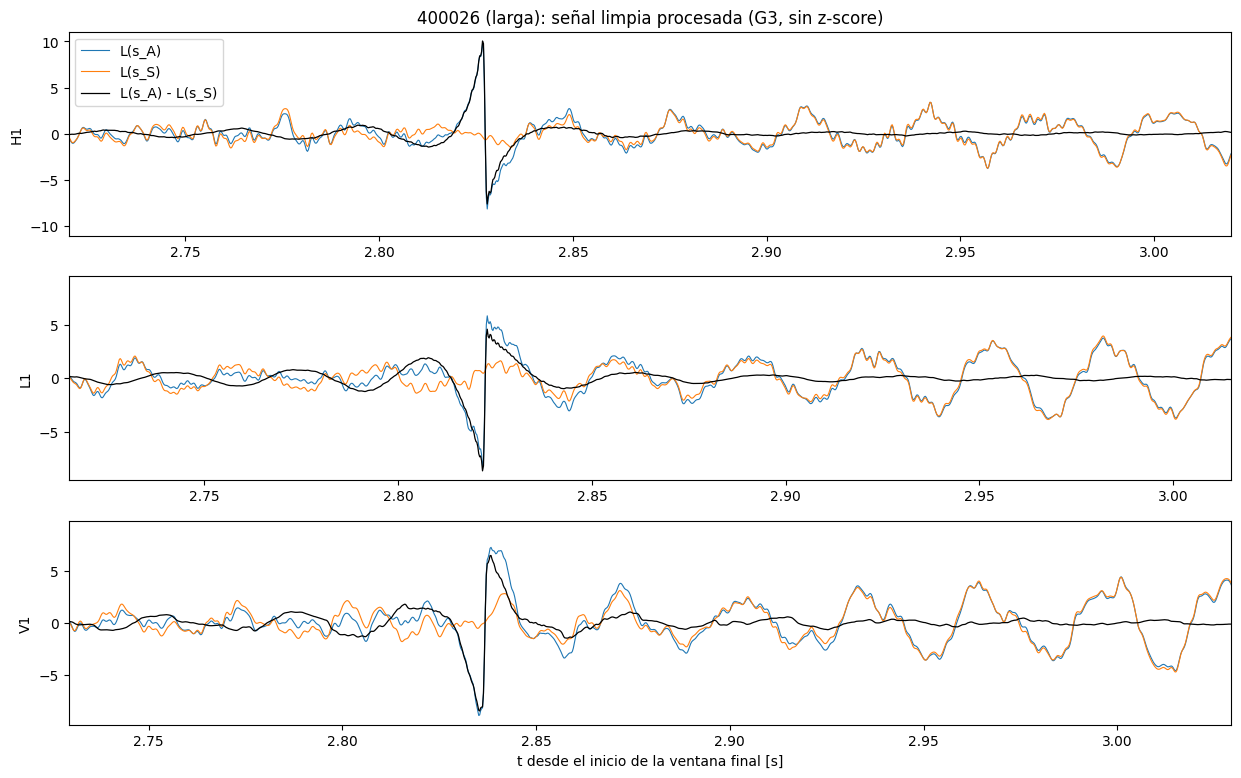

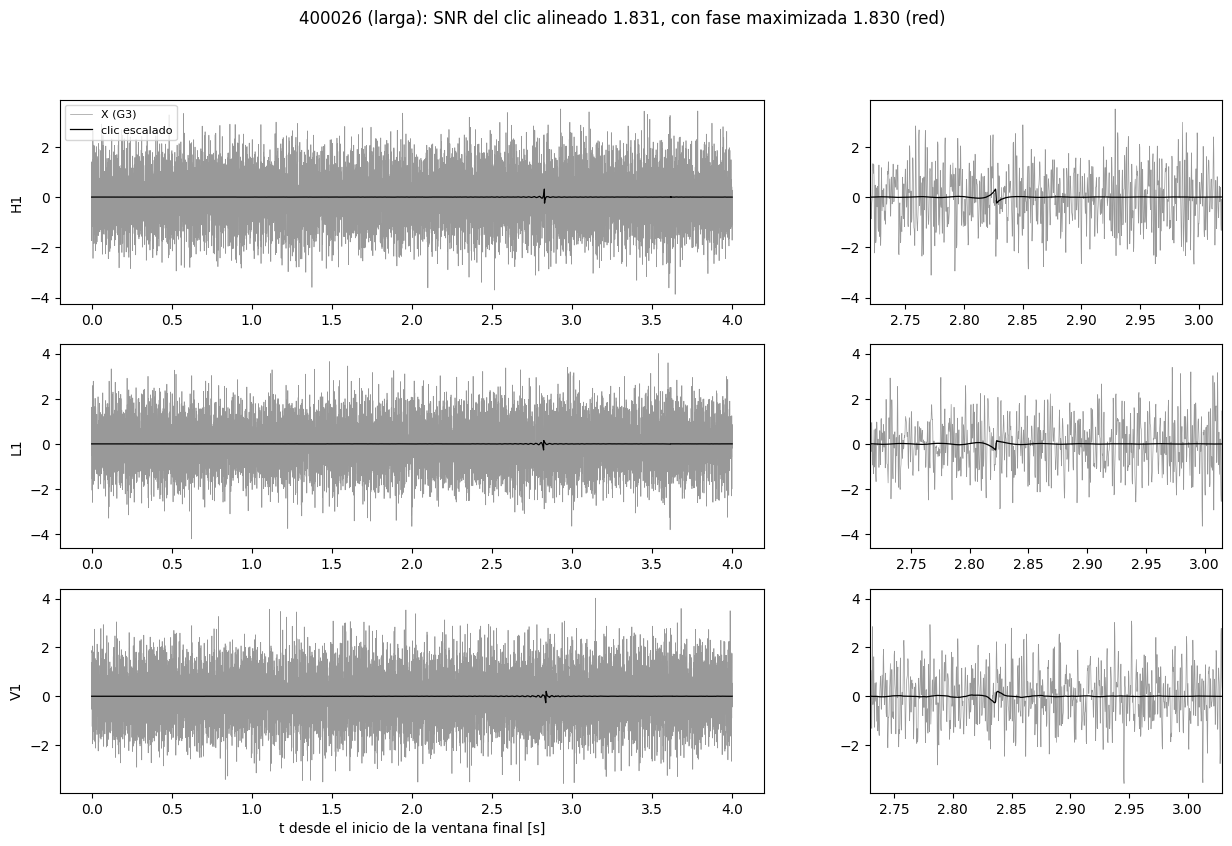

400026: max|L(s_E) - L(s_S)| / max|L(s_S)| = {'H1': 0.00485, 'L1': 0.00433, 'V1': 0.00376}


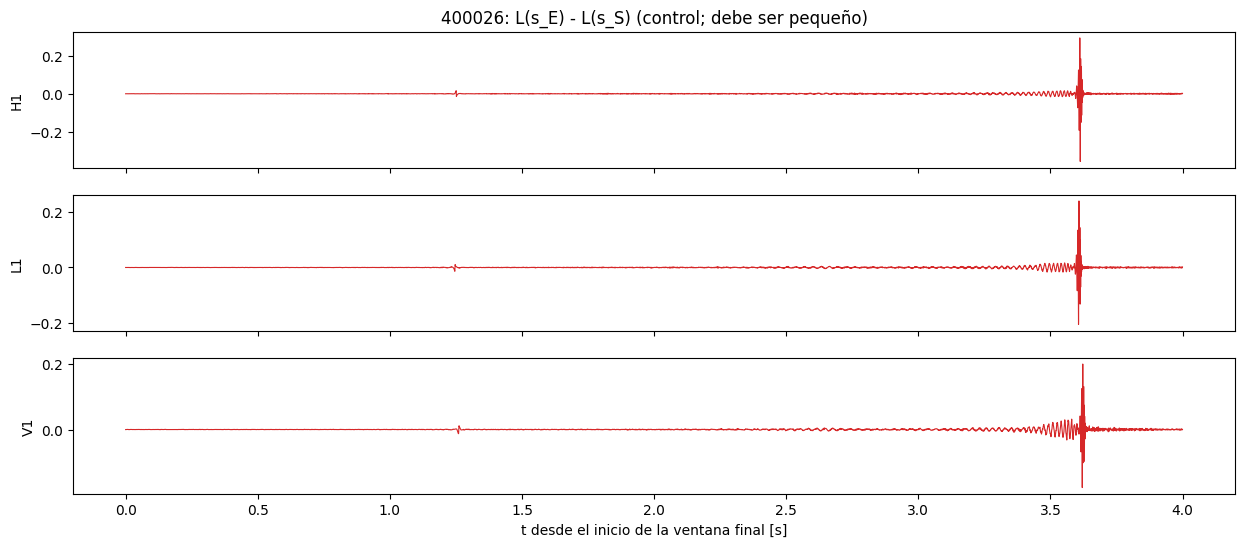

In [6]:
# 6. Lo que ve la red (paneles 4-6): proyección real, ventana final de 4 s
t = np.arange(g1.CONFIG.length) * DT   # s desde el inicio de la ventana final
for index, r in R.items():
    cap, fs, d = r['cap'], r['final_start'], r['click']
    LA = L(cap.signal['projection'].strains, r)
    S_hp, S_hc, _ = pr._opt_click_free_aligned(r['opt_args'])
    LS = L(project(S_hp, S_hc, cap), r)
    E_hp, E_hc, _ = pr.opt_extended_aligned(r['opt_args'])
    LE = L(project(E_hp, E_hc, cap), r)
    D = LA - LS
    # Inicio de la señal A en cada detector, relativo a la ventana (0 si empieza antes: señal truncada).
    t0 = {ifo: max(float(cap.signal['projection'].strains[ifo].start_time) - fs, 0.0) for ifo in DETECTORS}

    # Panel 4: L(s_A), L(s_S) y su diferencia, zoom en el inicio de la señal
    fig, ax = plt.subplots(3, 1, figsize=(15, 9))
    for i, ifo in enumerate(DETECTORS):
        a = ax[i]
        a.plot(t, LA[i], lw=0.8, label='L(s_A)')
        a.plot(t, LS[i], lw=0.8, label='L(s_S)')
        a.plot(t, D[i], lw=0.9, color='k', label='L(s_A) - L(s_S)')
        zoom(a, [(t, LA[i]), (t, LS[i]), (t, D[i])], t0[ifo] - 0.1, t0[ifo] + 0.2)
        a.set_ylabel(ifo)
    ax[0].legend(loc='upper left')
    ax[-1].set_xlabel('t desde el inicio de la ventana final [s]')
    ax[0].set_title(f'{index} ({ROWS[index]}): señal limpia procesada (G3, sin z-score)')
    plt.show()

    # Panel 5: X real (z-score) con el clic escalado por el mismo factor del z-score
    X_raw = pr.g6.stack_raw(g1.PROCESSOR.process_network(strains=cap.strains, psds=cap.psds))
    factor = r['X'].std(axis=1) / X_raw.std(axis=1)   # X = zscore(X_raw): escala por detector
    snr_al, snr_pm = d['snr_click_aligned_network'], d['snr_click_phasemax_network']
    fig, ax = plt.subplots(3, 2, figsize=(15, 9), gridspec_kw=dict(width_ratios=[2, 1]))
    for i, ifo in enumerate(DETECTORS):
        for a in ax[i]:
            a.plot(t, r['X'][i], lw=0.5, color='0.6', label='X (G3)')
            a.plot(t, factor[i] * D[i], lw=0.9, color='k', label='clic escalado')
        ax[i, 1].set_xlim(t0[ifo] - 0.1, t0[ifo] + 0.2)
        ax[i, 0].set_ylabel(ifo)
    ax[0, 0].legend(loc='upper left', fontsize=8)
    ax[-1, 0].set_xlabel('t desde el inicio de la ventana final [s]')
    fig.suptitle(f'{index} ({ROWS[index]}): SNR del clic alineado {snr_al:.3f}, '
                 f'con fase maximizada {snr_pm:.3f} (red)')
    plt.show()

    # Panel 6: control señal real, L(proyección de E) frente a L(proyección de S)
    ratio = np.abs(LE - LS).max(axis=1) / np.abs(LS).max(axis=1)
    print(f'{index}: max|L(s_E) - L(s_S)| / max|L(s_S)| =', dict(zip(DETECTORS, np.round(ratio, 5).tolist())))
    fig, ax = plt.subplots(3, 1, figsize=(15, 6), sharex=True)
    for i, ifo in enumerate(DETECTORS):
        ax[i].plot(t, LE[i] - LS[i], lw=0.8, color='C3')
        ax[i].set_ylabel(ifo)
    ax[-1].set_xlabel('t desde el inicio de la ventana final [s]')
    ax[0].set_title(f'{index}: L(s_E) - L(s_S) (control; debe ser pequeño)')
    plt.show()

/data/vserrano/cbc_pe_data/results/M13_3/M13_11/rows/20261104T174839Z/gates.json | 6 filas


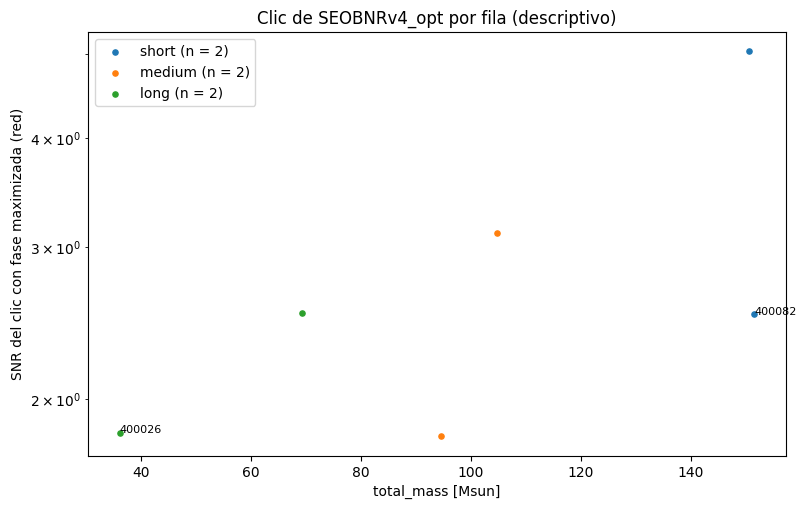

In [7]:
# 7. Resumen de las 180 filas: SNR del clic con fase maximizada frente a la masa total
def has_click(p):
    rows = (json.loads(p.read_text()).get('diag_click') or {}).get('rows') or []
    return bool(rows) and 'snr_click_phasemax_network' in rows[0]['data']


if GATES_JSON is None:
    runs = sorted((DATA_ROOT / 'results' / 'M13_3' / 'M13_11' / 'rows').glob('*/gates.json'))
    runs = [p for p in runs if has_click(p)]
    pr.require(runs, 'No gates.json with diag_click found')
    GATES_JSON = runs[-1]
GATES_JSON = Path(GATES_JSON)
gates = json.loads(GATES_JSON.read_text())
sel = json.loads((GATES_JSON.parent / 'selection.json').read_text())
mtot = {r['row_index']: r['y']['total_mass'] for r in sel['rows']}
rows = gates['diag_click']['rows']
print(GATES_JSON, '|', len(rows), 'filas')

fig, a = plt.subplots(figsize=(9, 5.5))
for k, reg in enumerate(pr.REGIMES):
    rs = [x for x in rows if x['regime'] == reg]
    a.scatter([mtot[x['row_index']] for x in rs], [x['data']['snr_click_phasemax_network'] for x in rs],
              s=14, color=f'C{k}', label=f'{reg} (n = {len(rs)})')
for x in rows:
    if x['row_index'] in ROWS:
        a.annotate(str(x['row_index']), (mtot[x['row_index']], x['data']['snr_click_phasemax_network']), fontsize=8)
a.set_yscale('log')
a.set_xlabel('total_mass [Msun]')
a.set_ylabel('SNR del clic con fase maximizada (red)')
a.set_title('Clic de SEOBNRv4_opt por fila (descriptivo)')
a.legend()
plt.show()